# Previsão da rede de fast food a partir de informações nutricionais

## 1. Base de dados
Leitura da base *Fast Food Nutrition Menu* (Kaggle), com itens de cardápio de seis redes.

- `! pip install ... -q`: instala as bibliotecas pelo terminal. O `!` executa um comando do sistema e o `-q` deixa a instalação silenciosa.
- `import pandas as pd`: carrega o pandas, biblioteca para trabalhar com tabelas, usando o apelido `pd`.
- `pd.read_csv(...)`: lê o arquivo CSV e cria o DataFrame `df`, que é a tabela na memória.

In [1]:
! pip install pandas -q
! pip install scikit-learn -q 
! pip install matplotplib -q
import pandas as pd

df= pd.read_csv('../dados/FastFoodNutritionMenuV3.csv')



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Could not find a version that satisfies the requirement matplotplib (from versions: none)

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for matplotplib


## 2. Reconhecimento dos dados
- `df`: exibe a tabela. O pandas mostra só o começo e o fim quando ela é grande.

In [2]:
df

,Company,Item,Calories,Calories from\nFat,Total Fat\n(g),Saturated Fat\n(g),Trans Fat\n(g),Cholesterol\n(mg),Sodium \n(mg),Carbs\n(g),Fiber\n(g),Sugars\n(g),Protein\n(g),Weight Watchers\nPnts
0,McDonald’s,Hamburger,250,80,9,3.5,0.5,25,520,31,2,6,12,247.5
1,McDonald’s,Cheeseburger,300,110,12,6,0.5,40,750,33,2,6,15,297
2,McDonald’s,Double Cheeseburger,440,210,23,11,1.5,80,1150,34,2,7,25,433
3,McDonald’s,McDouble,390,170,19,8,1,65,920,33,2,7,22,383
4,McDonald’s,Quarter Pounder® with Cheese,510,230,26,12,1.5,90,1190,40,3,9,29,502
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1142,Pizza Hut,Hand Tossed Slices Ultimate Cheese Lover’s® Me...,230,NaN,10,4.5,0,25,390,25,2,1,11,NaN
1143,Pizza Hut,Hand Tossed Slices Ultimate Cheese Lover’s® Large,310,NaN,13,6,0,35,540,33,2,1,15,NaN
1144,Pizza Hut,Hand Tossed Slices Veggie Lover’s® Small,120,NaN,4,1.5,0,10,230,17,1,1,5,NaN
1145,Pizza Hut,Hand Tossed Slices Veggie Lover’s® Medium,200,NaN,6,2.5,0,15,370,27,2,2,8,NaN


- `df.shape`: devolve (linhas, colunas). A base tem 1.147 itens e 14 variáveis.

In [3]:
df.shape

(1147, 14)

- `df.head()`: mostra as 5 primeiras linhas. Aceita um número (`head(10)`).

In [4]:
df.head()

,Company,Item,Calories,Calories from\nFat,Total Fat\n(g),Saturated Fat\n(g),Trans Fat\n(g),Cholesterol\n(mg),Sodium \n(mg),Carbs\n(g),Fiber\n(g),Sugars\n(g),Protein\n(g),Weight Watchers\nPnts
0,McDonald’s,Hamburger,250,80,9,3.5,0.5,25,520,31,2,6,12,247.5
1,McDonald’s,Cheeseburger,300,110,12,6,0.5,40,750,33,2,6,15,297
2,McDonald’s,Double Cheeseburger,440,210,23,11,1.5,80,1150,34,2,7,25,433
3,McDonald’s,McDouble,390,170,19,8,1,65,920,33,2,7,22,383
4,McDonald’s,Quarter Pounder® with Cheese,510,230,26,12,1.5,90,1190,40,3,9,29,502


- `df.tail()`: mostra as 5 últimas linhas.

In [5]:
df.tail()

,Company,Item,Calories,Calories from\nFat,Total Fat\n(g),Saturated Fat\n(g),Trans Fat\n(g),Cholesterol\n(mg),Sodium \n(mg),Carbs\n(g),Fiber\n(g),Sugars\n(g),Protein\n(g),Weight Watchers\nPnts
1142,Pizza Hut,Hand Tossed Slices Ultimate Cheese Lover’s® Me...,230,NaN,10,4.5,0,25,390,25,2,1,11,NaN
1143,Pizza Hut,Hand Tossed Slices Ultimate Cheese Lover’s® Large,310,NaN,13,6,0,35,540,33,2,1,15,NaN
1144,Pizza Hut,Hand Tossed Slices Veggie Lover’s® Small,120,NaN,4,1.5,0,10,230,17,1,1,5,NaN
1145,Pizza Hut,Hand Tossed Slices Veggie Lover’s® Medium,200,NaN,6,2.5,0,15,370,27,2,2,8,NaN
1146,Pizza Hut,Hand Tossed Slices Veggie Lover’s® Large,260,NaN,9,4,0,20,510,36,3,3,11,NaN


- `df.sample(10)`: sorteia 10 linhas. É útil porque a base está ordenada por rede, e o `head` e o `tail` mostram só as primeiras e as últimas.

In [6]:
df.sample(10)

,Company,Item,Calories,Calories from\nFat,Total Fat\n(g),Saturated Fat\n(g),Trans Fat\n(g),Cholesterol\n(mg),Sodium \n(mg),Carbs\n(g),Fiber\n(g),Sugars\n(g),Protein\n(g),Weight Watchers\nPnts
218,McDonald’s,Nonfat Vanilla Cappuccino (Small),150,0,0,0,0,5,70,34,0,34,5,179
438,Burger King,Smoothie: Strawberry Banana 16 fl oz,310,10,1,0,0,0,55,71,3,50,4,356
168,McDonald’s,POWERade® Mountain Blast (Small),100,0,0,0,0,0,85,27,0,21,0,121
269,McDonald’s,Caramel Latte (Large),330,80,9,5,0,30,210,52,0,51,9,377
847,KFC,Mountain Dew® (30 fl oz),410,NaN,0,0,0,0,125,110,0,109,0,519
193,McDonald’s,Iced Coffee with Sugar Free Vanilla Syrup (Small),60,50,5,3.5,0,20,70,8,0,1,1,63.5
969,Taco Bell,Mtn Dew® Baja Blast Freeze™ (16 oz),150,0,0,0,0,0,45,41,0,41,0,NaN
31,McDonald’s,Angus Deluxe Snack Wrap,410,220,25,10,1.5,75,990,27,2,3,20,403
959,Taco Bell,Hot Sauce Packet (V),0,0,0,0,0,0,45,0,0,0,0,NaN
295,McDonald’s,Iced Latte (Medium),100,50,6,3.5,0,15,80,8,0,8,6,105.5


- `df.columns.tolist()`: lista os nomes das colunas. Alguns têm quebra de linha (`\n`), o que atrapalha o acesso.

In [7]:
df.columns.tolist()

['Company',
 'Item',
 'Calories',
 'Calories from\nFat',
 'Total Fat\n(g)',
 'Saturated Fat\n(g)',
 'Trans Fat\n(g)',
 'Cholesterol\n(mg)',
 'Sodium \n(mg)',
 'Carbs\n(g)',
 'Fiber\n(g)',
 'Sugars\n(g)',
 'Protein\n(g)',
 'Weight Watchers\nPnts']

- `df.info()`: mostra o tipo de cada coluna e quantos valores não nulos ela tem.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1147 entries, 0 to 1146
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Company               1147 non-null   str  
 1   Item                  1147 non-null   str  
 2   Calories              1147 non-null   str  
 3   Calories from
Fat     642 non-null    str  
 4   Total Fat
(g)         1091 non-null   str  
 5   Saturated Fat
(g)     1091 non-null   str  
 6   Trans Fat
(g)         1091 non-null   str  
 7   Cholesterol
(mg)      1147 non-null   str  
 8   Sodium 
(mg)          1147 non-null   str  
 9   Carbs
(g)             1091 non-null   str  
 10  Fiber
(g)             1091 non-null   str  
 11  Sugars
(g)            1147 non-null   str  
 12  Protein
(g)           1091 non-null   str  
 13  Weight Watchers
Pnts  887 non-null    str  
dtypes: str(14)
memory usage: 125.6 KB


- `df.dtypes`: mostra só o tipo de cada coluna. As variáveis nutricionais aparecem como texto, quando deveriam ser números.

In [9]:
df.dtypes

Company                  str
Item                     str
Calories                 str
Calories from\nFat       str
Total Fat\n(g)           str
Saturated Fat\n(g)       str
Trans Fat\n(g)           str
Cholesterol\n(mg)        str
Sodium \n(mg)            str
Carbs\n(g)               str
Fiber\n(g)               str
Sugars\n(g)              str
Protein\n(g)             str
Weight Watchers\nPnts    str
dtype: object

- `df.isna()`: marca com `True` onde falta valor.
- `.sum()`: soma esses `True` por coluna, mostrando a quantidade de nulos de cada uma.

In [10]:
df.isna().sum()   

Company                    0
Item                       0
Calories                   0
Calories from\nFat       505
Total Fat\n(g)            56
Saturated Fat\n(g)        56
Trans Fat\n(g)            56
Cholesterol\n(mg)          0
Sodium \n(mg)              0
Carbs\n(g)                56
Fiber\n(g)                56
Sugars\n(g)                0
Protein\n(g)              56
Weight Watchers\nPnts    260
dtype: int64

- `df.duplicated()`: marca as linhas que repetem uma anterior.
- `.sum()`: conta quantas são. Resultado: 7 duplicatas.

In [11]:
df.duplicated().sum() 

np.int64(7)

- `df.describe()`: resume as colunas numéricas (média, mínimo, máximo, quartis). Como as variáveis ainda estão como texto, o resumo é limitado, o que reforça a necessidade de conversão.

In [12]:
df.describe()    

,Company,Item,Calories,Calories from\nFat,Total Fat\n(g),Saturated Fat\n(g),Trans Fat\n(g),Cholesterol\n(mg),Sodium \n(mg),Carbs\n(g),Fiber\n(g),Sugars\n(g),Protein\n(g),Weight Watchers\nPnts
count,1147,1147,1147,642,1091,1091,1091,1147,1147,1091,1091,1147,1091,887
unique,6,1071,105,64,73,35,11,65,214,131,17,122,56,524
top,McDonald’s,20 fl oz,0,0,0,0,0,0,0,0,0,0,0,0
freq,328,11,83,175,357,383,954,378,54,75,551,190,314,67


- `include="all"`: inclui também as colunas de texto (valores únicos e mais frequentes).
- `.T`: transpõe a tabela (troca linhas por colunas) para facilitar a leitura.

In [13]:
df.describe(include="all").T

,count,unique,top,freq
Company,1147,6,McDonald’s,328
Item,1147,1071,20 fl oz,11
Calories,1147,105,0,83
Calories from\nFat,642,64,0,175
Total Fat\n(g),1091,73,0,357
Saturated Fat\n(g),1091,35,0,383
Trans Fat\n(g),1091,11,0,954
Cholesterol\n(mg),1147,65,0,378
Sodium \n(mg),1147,214,0,54
Carbs\n(g),1091,131,0,75


## 3. Tratamento dos dados
**Padronização dos nomes das colunas.**

- `df.columns`: lista de nomes das colunas. Atribuir um valor a ela troca os nomes.
- `.str.replace("\n", " ", regex=False)`: troca a quebra de linha por espaço. `regex=False` indica que `\n` é um texto comum.
- `.str.replace(r"\s+", " ", regex=True)`: expressão regular em que `\s+` significa "um ou mais espaços seguidos", que viram um só.
- `.str.strip()`: remove espaços do início e do fim.

Exemplo: `"Total Fat\n(g)"` vira `"Total Fat (g)"`.

In [14]:
df.columns = (df.columns
              .str.replace("\n", " ", regex=False)
              .str.replace(r"\s+", " ", regex=True)
              .str.strip())

- `df.rename(columns={antigo: novo})`: troca os nomes usando um dicionário (pares nome antigo → nome novo). Os novos nomes são curtos, em português e sem espaços, o que facilita o código.

In [15]:
df = df.rename(columns={
    "Company": "empresa", "Item": "item", "Calories": "calorias",
    "Calories from Fat": "calorias_gordura", "Total Fat (g)": "gordura_total_g",
    "Saturated Fat (g)": "gordura_saturada_g", "Trans Fat (g)": "gordura_trans_g",
    "Cholesterol (mg)": "colesterol_mg", "Sodium (mg)": "sodio_mg",
    "Carbs (g)": "carboidratos_g", "Fiber (g)": "fibras_g",
    "Sugars (g)": "acucares_g", "Protein (g)": "proteina_g",
    "Weight Watchers Pnts": "ww_pontos",
})

**Limpeza de texto** nas colunas `empresa` e `item`.

- `.str.strip()`: remove espaços das pontas.
- `.str.replace(r"\s+", " ", regex=True)`: reduz espaços repetidos a um só.

Sem isso, `" McChicken"` e `"McChicken"` seriam tratados como itens diferentes.

In [16]:
df["empresa"] = df["empresa"].str.strip().str.replace(r"\s+", " ", regex=True)
df["item"] = df["item"].str.strip().str.replace(r"\s+", " ", regex=True)

**Tratamento de nulos (1/2).**

- `df.replace(padrão, valor, regex=True)`: troca valores que combinam com o padrão.
- `r"^\s*$"`: célula vazia ou só com espaços (`^` é o início, `\s*` são zero ou mais espaços, `$` é o fim).
- `float("nan")`: o valor de "dado ausente" que o pandas reconhece.

In [17]:
df = df.replace(r"^\s*$", float("nan"), regex=True)

**Conversão de texto para número.**

- `df.columns[2:]`: todas as colunas a partir da terceira, pulando `empresa` e `item`.
- `for c in colunas_num`: repete o tratamento para cada coluna.
- `.replace({"<1": "0.5", "<5": "2.5"})`: troca valores como "menos de 1" por uma aproximação (0,5 e 2,5).
- `pd.to_numeric(..., errors="coerce")`: converte para número. O que não puder ser convertido vira nulo.

In [18]:
colunas_num = df.columns[2:]
for c in colunas_num:
    df[c] = df[c].replace({"<1": "0.5", "<5": "2.5"})
    df[c] = pd.to_numeric(df[c], errors="coerce")

**Correção de linhas deslocadas** (54 linhas, em bebidas do Taco Bell, com valores nas colunas erradas).

- `desl = (...)`: cria uma máscara de verdadeiro/falso que marca as linhas com gordura e carboidratos vazios, mas com calorias preenchidas. `&` significa "e", `.isna()` é "está vazio" e `.notna()` é "não está vazio".
- `df.loc[linhas, coluna] = ...`: seleciona só essas linhas e uma coluna para atribuir um valor.
- O sódio é copiado para carboidratos, o colesterol para sódio, e o colesterol fica vazio. A ordem importa, para não sobrescrever um valor antes de copiá-lo.

In [19]:
desl = (df["gordura_total_g"].isna() & df["carboidratos_g"].isna()
        & df["calorias"].notna())
df.loc[desl, "carboidratos_g"] = df.loc[desl, "sodio_mg"]
df.loc[desl, "sodio_mg"] = df.loc[desl, "colesterol_mg"]
df.loc[desl, "colesterol_mg"] = float("nan")

**Remoção do que não será usado.**

- `drop(columns=["ww_pontos"])`: remove a coluna de pontos Weight Watchers, que tem valores inconsistentes.
- `drop_duplicates()`: remove linhas repetidas.
- `dropna(subset=["item", "calorias"])`: remove linhas em que o item ou as calorias estão vazios, que não têm informação útil.
- `reset_index(drop=True)`: renumera as linhas de 0 em diante.

In [20]:
df = df.drop(columns=["ww_pontos"])
df = df.drop_duplicates()
df = df.dropna(subset=["item", "calorias"]).reset_index(drop=True)


- `astype("category")`: converte `empresa` para o tipo categórico, indicado quando há poucos valores possíveis (aqui, 6 redes). Ocupa menos memória e permite acessar as categorias com `.cat`.

In [21]:
df["empresa"] = df["empresa"].astype("category")

**Salvando a base tratada.**

- `to_csv("fastfood_limpo.csv", index=False)`: grava um arquivo novo, sem alterar o original. `index=False` evita gravar a numeração das linhas como coluna extra.
- `print(df.shape)`: mostra o tamanho final: 1.126 linhas e 13 colunas.

In [22]:
df.to_csv("fastfood_limpo.csv", index=False)
print(df.shape)

(1126, 13)


- `df`: visualização da base já tratada.

In [23]:
df

,empresa,item,calorias,calorias_gordura,gordura_total_g,gordura_saturada_g,gordura_trans_g,colesterol_mg,sodio_mg,carboidratos_g,fibras_g,acucares_g,proteina_g
0,McDonald’s,Hamburger,250.0,80.0,9.0,3.5,0.5,25.0,520.0,31.0,2.0,6.0,12.0
1,McDonald’s,Cheeseburger,300.0,110.0,12.0,6.0,0.5,40.0,750.0,33.0,2.0,6.0,15.0
2,McDonald’s,Double Cheeseburger,440.0,210.0,23.0,11.0,1.5,80.0,1150.0,34.0,2.0,7.0,25.0
3,McDonald’s,McDouble,390.0,170.0,19.0,8.0,1.0,65.0,920.0,33.0,2.0,7.0,22.0
4,McDonald’s,Quarter Pounder® with Cheese,510.0,230.0,26.0,12.0,1.5,90.0,1190.0,40.0,3.0,9.0,29.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1121,Pizza Hut,Hand Tossed Slices Ultimate Cheese Lover’s® Me...,230.0,NaN,10.0,4.5,0.0,25.0,390.0,25.0,2.0,1.0,11.0
1122,Pizza Hut,Hand Tossed Slices Ultimate Cheese Lover’s® Large,310.0,NaN,13.0,6.0,0.0,35.0,540.0,33.0,2.0,1.0,15.0
1123,Pizza Hut,Hand Tossed Slices Veggie Lover’s® Small,120.0,NaN,4.0,1.5,0.0,10.0,230.0,17.0,1.0,1.0,5.0
1124,Pizza Hut,Hand Tossed Slices Veggie Lover’s® Medium,200.0,NaN,6.0,2.5,0.0,15.0,370.0,27.0,2.0,2.0,8.0


## 4. Aplicação do modelo de IA
**Objetivo:** prever a rede de fast food (coluna `empresa`) a partir das informações nutricionais de um item. É um problema de classificação, e o modelo escolhido foi o Random Forest.

Bibliotecas importadas:
- `RandomForestClassifier`: o modelo.
- `train_test_split`: divide os dados em treino e validação.
- `accuracy_score`, `classification_report`: medem o desempenho do modelo.
- `LabelEncoder`: transforma categorias em números.
- `joblib`: salva e carrega o modelo treinado.

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
import joblib

- `colunas = [...]`: lista das 9 variáveis nutricionais que serão a entrada do modelo.
- `df.dropna(subset=colunas)`: remove linhas com valores vazios nessas colunas, porque o modelo não aceita nulos (por exemplo, bebidas sem gordura informada).
- `.copy()`: cria uma cópia independente, para não alterar o `df`.

In [25]:
colunas = ["calorias", "gordura_total_g", "gordura_saturada_g", "colesterol_mg",
           "sodio_mg", "carboidratos_g", "fibras_g", "acucares_g", "proteina_g"]
d = df.dropna(subset=colunas).copy()

**Transformação da categoria em número.**

- `LabelEncoder()`: cria o codificador.
- `fit_transform(...)`: o `fit` aprende quais categorias existem e o `transform` converte cada uma em um código. O resultado vai para a coluna `empresa_cod`.
- `.astype(str)`: garante que os valores sejam texto.
- `drop_duplicates().sort_values("empresa_cod")`: mostra a tabela de correspondência (Burger King = 0, KFC = 1, McDonald's = 2, Pizza Hut = 3, Taco Bell = 4, Wendy's = 5).

In [26]:
codificador = LabelEncoder()
d["empresa_cod"] = codificador.fit_transform(d["empresa"].astype(str))
d[["empresa", "empresa_cod"]].drop_duplicates().sort_values("empresa_cod")

,empresa,empresa_cod
328,Burger King,0
654,KFC,1
0,McDonald’s,2
1052,Pizza Hut,3
872,Taco Bell,4
500,Wendy’s,5


- `X`: variáveis de entrada, que o modelo usa para decidir.
- `y`: variável que se quer prever, a rede.

In [27]:
X = d[colunas]
y = d["empresa_cod"]

**Separação dos dados em treino (70%) e validação (30%).**

- `train_test_split(X, y, ...)`: devolve quatro partes (`X_treino`, `X_validacao`, `y_treino`, `y_validacao`).
- `test_size=0.3`: 30% dos dados ficam para validação.
- `stratify=y`: mantém a proporção de cada rede nos dois grupos.
- `random_state=0`: fixa o sorteio, para o resultado ser repetível.
- `len(...)`: conta os itens de cada grupo (750 e 322).

In [28]:
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=0)
print(len(X_treino), len(X_validacao))

750 322


**Treinamento.**

- `RandomForestClassifier(n_estimators=300, random_state=0)`: cria um modelo com 300 árvores de decisão. Cada uma dá um "voto", e a rede mais votada é a previsão.
- `modelo.fit(X_treino, y_treino)`: treina o modelo, que aprende os padrões entre as variáveis nutricionais e a rede.

In [29]:
modelo = RandomForestClassifier(n_estimators=300, random_state=0)
modelo.fit(X_treino, y_treino)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

**Validação** com dados que o modelo não viu no treino.

- `modelo.predict(X_validacao)`: gera as previsões.
- `accuracy_score(...)`: proporção de acertos. `round(..., 3)` limita a 3 casas. Resultado: 0,643 (64,3%).
- `classification_report(...)`: tabela por rede com:
  - *precision*: quando o modelo prevê a rede, quanto ele acerta;
  - *recall*: dos itens reais da rede, quantos ele encontrou;
  - *f1-score*: combinação das duas medidas.

In [30]:
previsoes = modelo.predict(X_validacao)
print("Acerto na validação:", round(accuracy_score(y_validacao, previsoes), 3))
print(classification_report(y_validacao, previsoes, target_names=codificador.classes_))

Acerto na validação: 0.643
              precision    recall  f1-score   support

 Burger King       0.45      0.35      0.39        52
         KFC       0.63      0.57      0.60        65
  McDonald’s       0.63      0.84      0.72        99
   Pizza Hut       0.92      1.00      0.96        22
   Taco Bell       0.85      0.89      0.87        38
     Wendy’s       0.48      0.28      0.36        46

    accuracy                           0.64       322
   macro avg       0.66      0.66      0.65       322
weighted avg       0.62      0.64      0.62       322



**Exportação do modelo treinado.**

- `joblib.dump(objeto, arquivo)`: salva um objeto Python em arquivo.
- O dicionário guarda o modelo, o codificador (para traduzir o código de volta ao nome da rede) e a lista de colunas. Tudo vai para `modelo_rf.joblib`, usado pela interface.

In [31]:
joblib.dump({"modelo": modelo, "codificador": codificador, "colunas": colunas}, "modelo_rf.joblib")

['modelo_rf.joblib']

**Importância das variáveis.**

- `modelo.feature_importances_`: o quanto cada variável pesou nas decisões (a soma é 1).
- `pd.Series(..., index=colunas)`: associa cada valor ao nome da variável.
- `sort_values(ascending=False)`: ordena da maior para a menor. `round(3)` limita a 3 casas.

In [32]:
importancia = pd.Series(modelo.feature_importances_, index=colunas).sort_values(ascending=False)
print(importancia.round(3))

sodio_mg              0.201
carboidratos_g        0.155
acucares_g            0.153
calorias              0.107
colesterol_mg         0.092
proteina_g            0.085
fibras_g              0.081
gordura_total_g       0.070
gordura_saturada_g    0.057
dtype: float64


## 5. Gráficos

- `import matplotlib.pyplot as plt`: biblioteca de gráficos, com o apelido `plt`.
- `confusion_matrix`: função que calcula a matriz de confusão.
- `redes = list(codificador.classes_)`: nomes das 6 redes, na ordem dos códigos.
- `cores`: uma cor para cada rede, em código hexadecimal, mantida igual em todos os gráficos.

In [33]:
import tkinter as tk
from tkinter import ttk

pacote = joblib.load("modelo_rf.joblib")
modelo = pacote["modelo"]
codificador = pacote["codificador"]
colunas = pacote["colunas"]
redes = list(codificador.classes_)

rotulos = {
    "calorias": "Calorias",
    "gordura_total_g": "Gordura total (g)",
    "gordura_saturada_g": "Gordura saturada (g)",
    "colesterol_mg": "Colesterol (mg)",
    "sodio_mg": "Sódio (mg)",
    "carboidratos_g": "Carboidratos (g)",
    "fibras_g": "Fibras (g)",
    "acucares_g": "Açúcares (g)",
    "proteina_g": "Proteína (g)",
}
cores = ["#F28C28", "#D7263D", "#F2C14E", "#2E933C", "#6A4C93", "#1B98E0"]
fundo = "#F4F6F8"

validacao = d.loc[X_validacao.index]
minimos = d[colunas].min()
maximos = d[colunas].max()
medianas = d[colunas].median()

janela = tk.Tk()
janela.title("Previsor de rede de fast food")
janela.configure(bg=fundo)

estilo = ttk.Style()
estilo.theme_use("clam")
estilo.configure("TFrame", background=fundo)
estilo.configure("TLabelframe", background=fundo)
estilo.configure("TLabelframe.Label", background=fundo, font=("Arial", 10, "bold"))
estilo.configure("TLabel", background=fundo, font=("Arial", 10))
estilo.configure("Titulo.TLabel", font=("Arial", 16, "bold"))
estilo.configure("Rede.TLabel", font=("Arial", 22, "bold"), foreground="#1B4965")
estilo.configure("Sub.TLabel", foreground="#5C6770")
estilo.configure("TButton", font=("Arial", 10, "bold"), padding=6)
estilo.configure("Horizontal.TScale", background=fundo)
for i, cor in enumerate(cores):
    estilo.configure(f"Rede{i}.Horizontal.TProgressbar", background=cor, troughcolor="#DDE3E8", thickness=14)

def atualizar():
    entrada = pd.DataFrame([[valores[c].get() for c in colunas]], columns=colunas)
    for c in colunas:
        textos[c].set(f"{valores[c].get():.1f}")
    probabilidades = modelo.predict_proba(entrada)[0]
    melhor = probabilidades.argmax()
    resultado.set(redes[melhor])
    confianca.set(f"Confiança do modelo: {probabilidades[melhor] * 100:.0f}%")
    for i, p in enumerate(probabilidades):
        barras[i]["value"] = p * 100
        percentuais[i].set(f"{p * 100:.0f}%")
    return redes[melhor]

def ao_mover(_):
    comparacao.set("")
    atualizar()

def exemplo_real():
    linha = validacao.sample(1).iloc[0]
    for c in colunas:
        valores[c].set(float(linha[c]))
    prevista = atualizar()
    real = str(linha["empresa"])
    situacao = "✔ Acertou" if prevista == real else "✘ Errou"
    comparacao.set(f"Item: {linha['item']}\nRede real: {real}  |  {situacao}")

def limpar():
    for c in colunas:
        valores[c].set(float(medianas[c]))
    comparacao.set("")
    atualizar()

principal = ttk.Frame(janela, padding=20)
principal.grid()
ttk.Label(principal, text="Previsor de rede de fast food", style="Titulo.TLabel").grid(row=0, column=0, columnspan=2, sticky="w")
ttk.Label(principal, text="Mova os controles e veja a previsão do modelo em tempo real.", style="Sub.TLabel").grid(row=1, column=0, columnspan=2, sticky="w", pady=(0, 12))

entradas = ttk.LabelFrame(principal, text=" Valores nutricionais ", padding=12)
entradas.grid(row=2, column=0, sticky="n", padx=(0, 15))
saida = ttk.LabelFrame(principal, text=" Resultado ", padding=12)
saida.grid(row=2, column=1, sticky="n")

valores = {}
textos = {}
for i, c in enumerate(colunas):
    valores[c] = tk.DoubleVar(value=float(medianas[c]))
    textos[c] = tk.StringVar()
    ttk.Label(entradas, text=rotulos[c], width=20).grid(row=i, column=0, sticky="w", pady=4)
    ttk.Scale(entradas, from_=float(minimos[c]), to=float(maximos[c]), variable=valores[c],
              command=ao_mover, length=220).grid(row=i, column=1, padx=8)
    ttk.Label(entradas, textvariable=textos[c], width=7, anchor="e").grid(row=i, column=2)

resultado = tk.StringVar()
confianca = tk.StringVar()
comparacao = tk.StringVar()
ttk.Label(saida, textvariable=resultado, style="Rede.TLabel").grid(row=0, column=0, columnspan=3, sticky="w")
ttk.Label(saida, textvariable=confianca, style="Sub.TLabel").grid(row=1, column=0, columnspan=3, sticky="w", pady=(0, 10))

barras = []
percentuais = []
for i, rede in enumerate(redes):
    percentuais.append(tk.StringVar())
    ttk.Label(saida, text=rede, width=12).grid(row=i + 2, column=0, sticky="w", pady=3)
    barra = ttk.Progressbar(saida, style=f"Rede{i}.Horizontal.TProgressbar", length=180, maximum=100)
    barra.grid(row=i + 2, column=1, padx=8)
    barras.append(barra)
    ttk.Label(saida, textvariable=percentuais[i], width=5, anchor="e").grid(row=i + 2, column=2)

ttk.Label(saida, textvariable=comparacao, style="Sub.TLabel", wraplength=300, justify="left").grid(
    row=len(redes) + 2, column=0, columnspan=3, sticky="w", pady=(12, 0))

botoes = ttk.Frame(principal)
botoes.grid(row=3, column=0, columnspan=2, pady=(15, 0), sticky="e")
ttk.Button(botoes, text="Exemplo real", command=exemplo_real).grid(row=0, column=0, padx=5)
ttk.Button(botoes, text="Limpar", command=limpar).grid(row=0, column=1, padx=5)

atualizar()
janela.mainloop()

**Quantidade de itens por rede.**

- `value_counts()`: conta quantos itens há em cada rede. `reindex(redes)` coloca na ordem das redes.
- `plt.figure(figsize=(8, 5))`: define o tamanho da figura.
- `plt.bar(...)`: desenha barras verticais.
- `plt.title`, `plt.ylabel`: título e legenda do eixo.
- `plt.text(...)`: escreve o valor sobre cada barra.
- `plt.tight_layout()`: ajusta as margens.
- `plt.show()`: exibe o gráfico.

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

redes = list(codificador.classes_)
cores = ["#F28C28", "#D7263D", "#F2C14E", "#2E933C", "#6A4C93", "#1B98E0"]

**Distribuição de calorias por rede (boxplot).**

- `df.loc[df["empresa"] == r, "calorias"]`: seleciona as calorias de uma rede.
- `plt.boxplot(...)`: cada caixa mostra onde está a metade central dos itens, a linha interna é a mediana, os traços são a faixa normal e os círculos são valores extremos.
- `patch_artist=True`: permite colorir as caixas.
- `plt.xticks(...)`: coloca os nomes das redes no eixo.

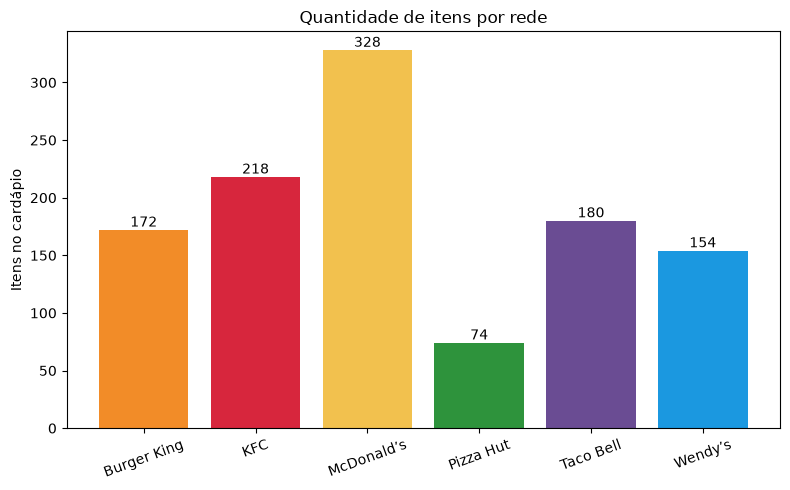

In [35]:
contagem = df["empresa"].value_counts().reindex(redes)

plt.figure(figsize=(8, 5))
plt.bar(redes, contagem.values, color=cores)
plt.title("Quantidade de itens por rede")
plt.ylabel("Itens no cardápio")
plt.xticks(rotation=20)
for i, v in enumerate(contagem.values):
    plt.text(i, v + 3, str(v), ha="center")
plt.tight_layout()
plt.show()

**Sódio médio por rede.**

- `groupby("empresa")["sodio_mg"].mean()`: agrupa os itens por rede e calcula a média de sódio de cada uma.
- `observed=True`: considera só as categorias que existem nos dados.

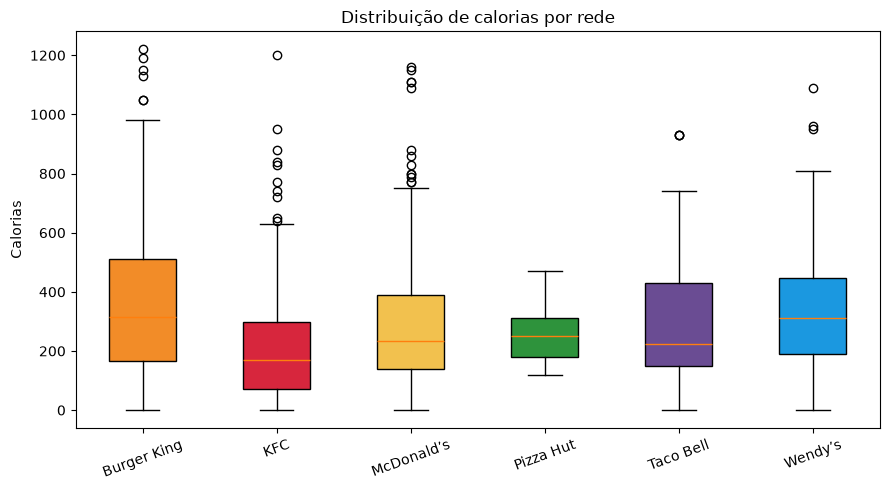

In [36]:
dados = [df.loc[df["empresa"] == r, "calorias"] for r in redes]

plt.figure(figsize=(9, 5))
caixas = plt.boxplot(dados, patch_artist=True)
for caixa, cor in zip(caixas["boxes"], cores):
    caixa.set_facecolor(cor)
plt.xticks(range(1, len(redes) + 1), redes, rotation=20)
plt.title("Distribuição de calorias por rede")
plt.ylabel("Calorias")
plt.tight_layout()
plt.show()

**Correlação entre as variáveis.**

- `df[colunas].corr()`: calcula a correlação entre cada par de variáveis, de -1 a 1. Perto de 1, as variáveis crescem juntas; perto de 0, não há relação.
- `plt.imshow(..., cmap="coolwarm")`: desenha a tabela como mapa de cores.
- `plt.colorbar()`: mostra a legenda das cores.
- `plt.text(...)` dentro dos laços: escreve o valor em cada quadrado.

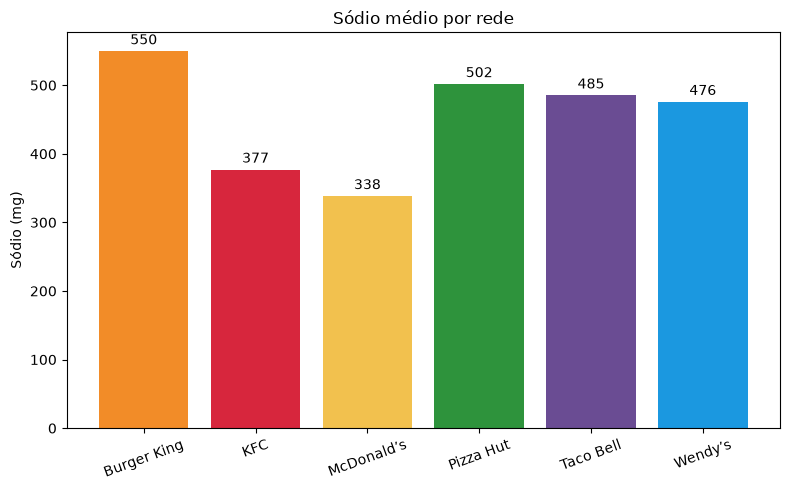

In [37]:
media_sodio = df.groupby("empresa", observed=True)["sodio_mg"].mean().reindex(redes)

plt.figure(figsize=(8, 5))
plt.bar(redes, media_sodio.values, color=cores)
plt.title("Sódio médio por rede")
plt.ylabel("Sódio (mg)")
plt.xticks(rotation=20)
for i, v in enumerate(media_sodio.values):
    plt.text(i, v + 10, f"{v:.0f}", ha="center")
plt.tight_layout()
plt.show()

**Importância das variáveis no Random Forest.**

- `importancia.sort_values()`: ordena os valores calculados anteriormente.
- `plt.barh(...)`: barras horizontais, boas para nomes longos.

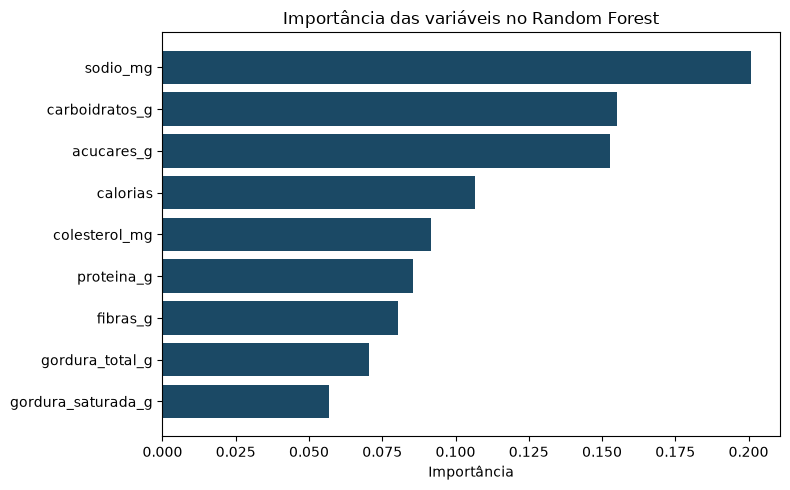

In [38]:
imp = importancia.sort_values()

plt.figure(figsize=(8, 5))
plt.barh(imp.index, imp.values, color="#1B4965")
plt.title("Importância das variáveis no Random Forest")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

**Matriz de confusão.**

- `confusion_matrix(y_validacao, previsoes)`: compara a rede real com a prevista.
- Cada linha é a rede real e cada coluna é a rede prevista. A diagonal mostra os acertos, e os outros valores mostram as confusões.
- `plt.xlabel`, `plt.ylabel`: legendas dos eixos.

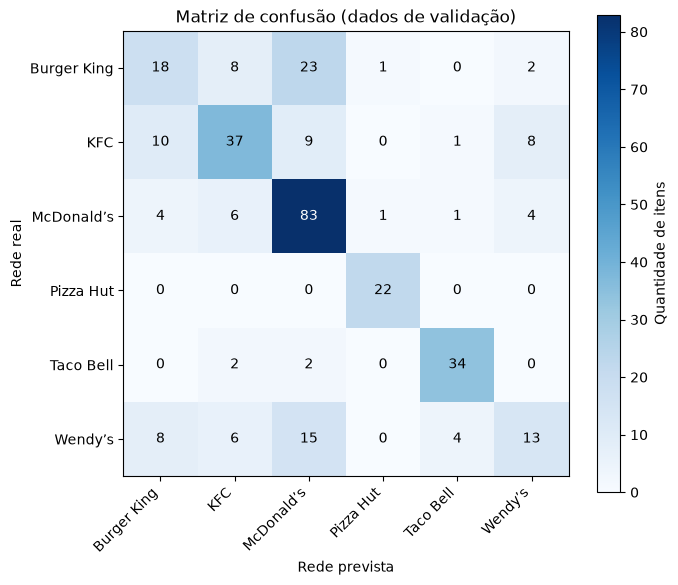

In [39]:
matriz = confusion_matrix(y_validacao, previsoes)

plt.figure(figsize=(7, 6))
plt.imshow(matriz, cmap="Blues")
plt.colorbar(label="Quantidade de itens")
plt.xticks(range(len(redes)), redes, rotation=45, ha="right")
plt.yticks(range(len(redes)), redes)
for i in range(len(redes)):
    for j in range(len(redes)):
        cor_texto = "white" if matriz[i, j] > matriz.max() / 2 else "black"
        plt.text(j, i, matriz[i, j], ha="center", va="center", color=cor_texto)
plt.xlabel("Rede prevista")
plt.ylabel("Rede real")
plt.title("Matriz de confusão (dados de validação)")
plt.tight_layout()
plt.show()

**Comparação com um chute.**

- `value_counts(normalize=True).max()`: proporção da rede mais frequente. Se o modelo sempre apostasse nela, acertaria cerca de 31%.
- `accuracy_score(...)`: acerto real do modelo (cerca de 64%).
- A diferença mostra que o modelo realmente aprendeu padrões.

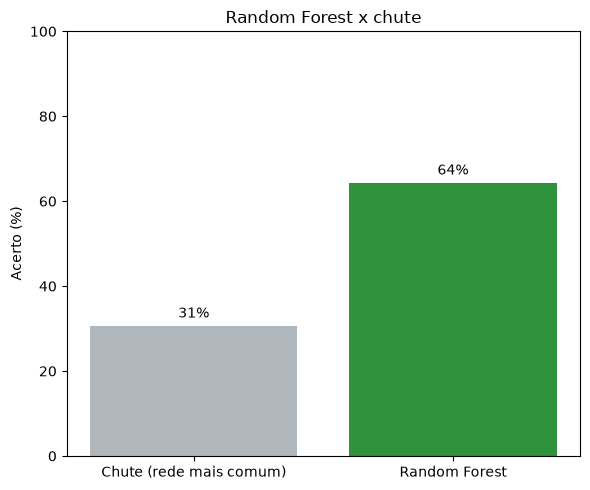

In [40]:
baseline = y.value_counts(normalize=True).max() * 100
acerto = accuracy_score(y_validacao, previsoes) * 100

plt.figure(figsize=(6, 5))
plt.bar(["Chute (rede mais comum)", "Random Forest"], [baseline, acerto], color=["#B0B7BD", "#2E933C"])
plt.ylim(0, 100)
plt.ylabel("Acerto (%)")
plt.title("Random Forest x chute")
for i, v in enumerate([baseline, acerto]):
    plt.text(i, v + 2, f"{v:.0f}%", ha="center")
plt.tight_layout()
plt.show()